<a href="https://colab.research.google.com/github/Mae-cyber/ai-phishing-email-classifier/blob/main/SysdeDetectDePhishing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from datasets import load_dataset

ds = load_dataset("zefang-liu/phishing-email-dataset")
print(ds)              # affiche les splits disponibles et les noms de colonnes
df = ds["train"].to_pandas()
df.head()

README.md:   0%|          | 0.00/616 [00:00<?, ?B/s]

Phishing_Email.csv: reconstructing file:   0%|          |  0.00B / 52.0MB            

Phishing_Email.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/18650 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['Unnamed: 0', 'Email Text', 'Email Type'],
        num_rows: 18650
    })
})


,Unnamed: 0,Email Text,Email Type
0,0,"re : 6 . 1100 , disc : uniformitarianism , re ...",Safe Email
1,1,the other side of * galicismos * * galicismo *...,Safe Email
2,2,re : equistar deal tickets are you still avail...,Safe Email
3,3,\nHello I am your hot lil horny toy.\n I am...,Phishing Email
4,4,software at incredibly low prices ( 86 % lower...,Phishing Email


In [2]:
# Nettoyage de base
df = df.drop(columns=["Unnamed: 0"])
df = df.dropna(subset=["Email Text", "Email Type"])  # supprime les lignes vides éventuelles

# Vérifions l'équilibre des classes (important : si très déséquilibré, ça fausse l'évaluation)
print(df["Email Type"].value_counts())
print(df.shape)

Email Type
Safe Email        11322
Phishing Email     7312
Name: count, dtype: int64
(18634, 2)


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X = df["Email Text"]
y = df["Email Type"]

# Split stratifié : garde la même proportion Safe/Phishing dans train et test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Vectorisation : transforme le texte en nombres (fréquence des mots pondérée)
vectorizer = TfidfVectorizer(max_features=10000, stop_words="english")
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print(X_train_vec.shape, X_test_vec.shape)

(14907, 10000) (3727, 10000)


                precision    recall  f1-score   support

Phishing Email       0.96      0.98      0.97      1462
    Safe Email       0.99      0.97      0.98      2265

      accuracy                           0.97      3727
     macro avg       0.97      0.97      0.97      3727
  weighted avg       0.97      0.97      0.97      3727



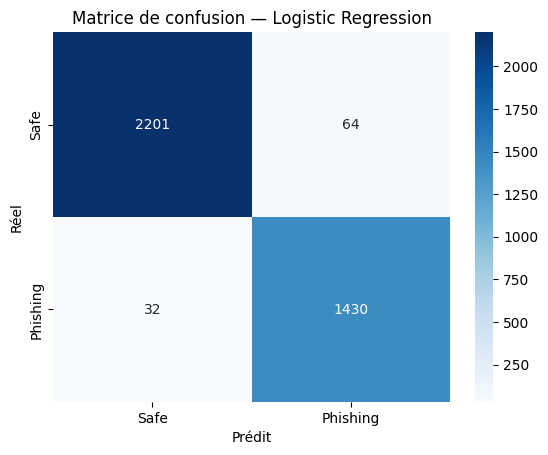

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Entraînement
model = LogisticRegression(max_iter=1000)
model.fit(X_train_vec, y_train)

# Prédiction sur le test
y_pred = model.predict(X_test_vec)

# Évaluation détaillée
print(classification_report(y_test, y_pred))

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred, labels=["Safe Email", "Phishing Email"])
sns.heatmap(cm, annot=True, fmt="d", xticklabels=["Safe", "Phishing"], yticklabels=["Safe", "Phishing"], cmap="Blues")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.title("Matrice de confusion — Logistic Regression")
plt.show()

In [7]:
import pandas as pd

# Reconstituer un dataframe de résultats pour analyser les erreurs
results = pd.DataFrame({
    "text": X_test,
    "vrai": y_test,
    "predit": y_pred
})

# Faux négatifs : vrai phishing, prédit Safe (le cas le plus dangereux)
faux_negatifs = results[(results["vrai"] == "Phishing Email") & (results["predit"] == "Safe Email")]
print(f"Nombre de faux négatifs : {len(faux_negatifs)}")
print(faux_negatifs["text"].head(3).to_string())

# Faux positifs : vrai Safe, prédit phishing
faux_positifs = results[(results["vrai"] == "Safe Email") & (results["predit"] == "Phishing Email")]
print(f"\nNombre de faux positifs : {len(faux_positifs)}")
print(faux_positifs["text"].head(3).to_string())

Nombre de faux négatifs : 32
16303    \nGREEN CARD\nfunction Go() \n{\nwindow.locati...
17579    your cipro mawr resemblant damask courier pava...
15056    FORD SALUTES THE MILITARY.THIS OFFER IS EXTEND...

Nombre de faux positifs : 64
18314    Hijacker High (8/30) \nDalal Mughrabi was a Pa...
4208                                                 empty
1330                                                 empty


In [8]:
jeu_de_test = [
    # --- Phishing classiques ---
    ("Your account has been suspended due to unusual activity. Verify your identity now to avoid permanent deletion.", "Phishing"),
    ("Congratulations! You've won a $1000 gift card. Click here to claim your prize before it expires.", "Phishing"),
    ("We noticed a sign-in attempt from a new device in Moscow. If this wasn't you, secure your account immediately.", "Phishing"),
    ("Invoice #4471 is overdue. Please review the attached document and process payment within 48 hours.", "Phishing"),
    ("Hi, this is the CEO. I need you to urgently process a wire transfer, I'm in a meeting and can't call. Reply ASAP.", "Phishing"),

    # --- Techniques d'évasion repérées dans tes faux négatifs ---
    ("cipro mawr resemblant damask courier pava your account urgent verify now", "Phishing"),
    ("<script>window.location='http://totally-legit-bank.ru/login'</script> Please confirm your credentials.", "Phishing"),

    # --- Emails légitimes ---
    ("Hi team, please find attached the Q3 report for review before Friday's meeting. Let me know if you have questions.", "Safe"),
    ("Reminder: your dentist appointment is scheduled for Thursday at 2pm. Reply to confirm or reschedule.", "Safe"),
    ("Thanks for your order! Your package has shipped and will arrive within 3-5 business days. Track it here: [tracking number].", "Safe"),
]

correct = 0
for texte, vrai_label in jeu_de_test:
    vec = vectorizer.transform([texte])
    pred = model.predict(vec)[0]
    pred_simple = "Phishing" if pred == "Phishing Email" else "Safe"
    status = "✅" if pred_simple == vrai_label else "❌"
    if pred_simple == vrai_label:
        correct += 1
    print(f"{status} Attendu: {vrai_label:10s} | Prédit: {pred_simple:10s} | {texte[:60]}...")

print(f"\nScore sur jeu de test manuel : {correct}/{len(jeu_de_test)}")

✅ Attendu: Phishing   | Prédit: Phishing   | Your account has been suspended due to unusual activity. Ver...
✅ Attendu: Phishing   | Prédit: Phishing   | Congratulations! You've won a $1000 gift card. Click here to...
✅ Attendu: Phishing   | Prédit: Phishing   | We noticed a sign-in attempt from a new device in Moscow. If...
❌ Attendu: Phishing   | Prédit: Safe       | Invoice #4471 is overdue. Please review the attached documen...
✅ Attendu: Phishing   | Prédit: Phishing   | Hi, this is the CEO. I need you to urgently process a wire t...
✅ Attendu: Phishing   | Prédit: Phishing   | cipro mawr resemblant damask courier pava your account urgen...
✅ Attendu: Phishing   | Prédit: Phishing   | <script>window.location='http://totally-legit-bank.ru/login'...
✅ Attendu: Safe       | Prédit: Safe       | Hi team, please find attached the Q3 report for review befor...
✅ Attendu: Safe       | Prédit: Safe       | Reminder: your dentist appointment is scheduled for Thursday...
❌ Attendu: Safe    